# Time Series Forecasting: Stationarity, Autocorrelation, and Why We Forecast Returns

**Target stock: GOOGL** (matching Notebooks 1, 3 and 4).

| Key | Value |
|:--|:--|
| **Course Codes** | BBT 4206 and BFS 4102 |
| **Semester** | September to November 2026 |
| **Lecturer** | Allan Omondi |
| **Group** | Group B6 — this notebook is Member 2's contribution |
| **Note** | Educational use only. Nothing here is investment advice. |


## What you will learn in this notebook

1. Spot stationarity **by eye** (rolling mean/standard deviation) and confirm it **statistically**
   with the ADF and KPSS tests.
2. Apply differencing and the log transform, and explain what each one fixes.
3. Read ACF and PACF plots.
4. Demonstrate **spurious regression** between two price series, and show why regressing returns
   instead fixes it.
5. Explain why the lab forecasts **returns**, not price.
6. Explain **volatility clustering** and fit a GARCH(1,1) model to it.

**Recall:** a series is (weakly) stationary when its mean, variance, and autocovariance do not
depend on *when* you look — only on the lag between two points.


## Step 1: Set Up the Notebook

In [1]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

if "google.colab" in sys.modules and not os.path.exists("tslab"):
    subprocess.run(
        ["git", "clone", "https://github.com/course-files/TimeSeriesForecastingandNeuralNetworks.git"],
        check=True,
    )
    os.chdir("TimeSeriesForecastingandNeuralNetworks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/colab.txt"], check=True)
    print("Colab workspace prepared.")


Python interpreter: c:\Users\guyfl\OneDrive\Documents\SU 4.2\TSF_1\.venv\Scripts\python.exe
Python version    : 3.12.10


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from arch import arch_model

from tslab import config
from tslab.data import load_market_data
from tslab.plots import plot_acf_pacf

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

assert config.TARGET_TICKER == "GOOGL", (
    "config.TARGET_TICKER must be set to 'GOOGL' in tslab/config.py "
    "to match the rest of the group's notebooks."
)


## Step 2: Build the Series

Four series, built once and reused throughout the notebook:


In [3]:
data = load_market_data()

price = data["Close"]
log_price = np.log(price)
price_change = price.diff()        # first difference of the raw price
log_return = log_price.diff()      # first difference of the log price ("the" return)

series = pd.DataFrame({
    "price": price,
    "log_price": log_price,
    "price_change": price_change,
    "log_return": log_return,
}).dropna()

series.head()


Loaded 2981 trading days of GOOGL, 2015-01-02 to 2026-11-09, with 7 predictor series.


,price,log_price,price_change,log_return
Date,,,,
2015-01-05,25.728174,3.247587,-0.499748,-0.019238
2015-01-06,25.093218,3.222598,-0.634956,-0.024989
2015-01-07,25.019424,3.219653,-0.073793,-0.002945
2015-01-08,25.106594,3.223131,0.087170,0.003478
2015-01-09,24.800014,3.210844,-0.306580,-0.012286


## Step 3: Look First — Rolling Statistics

Plot each series with a 63-day rolling mean and rolling standard deviation. A flat rolling mean
and a roughly flat rolling standard deviation suggest stationarity; a drifting mean or a
changing spread suggests the opposite.


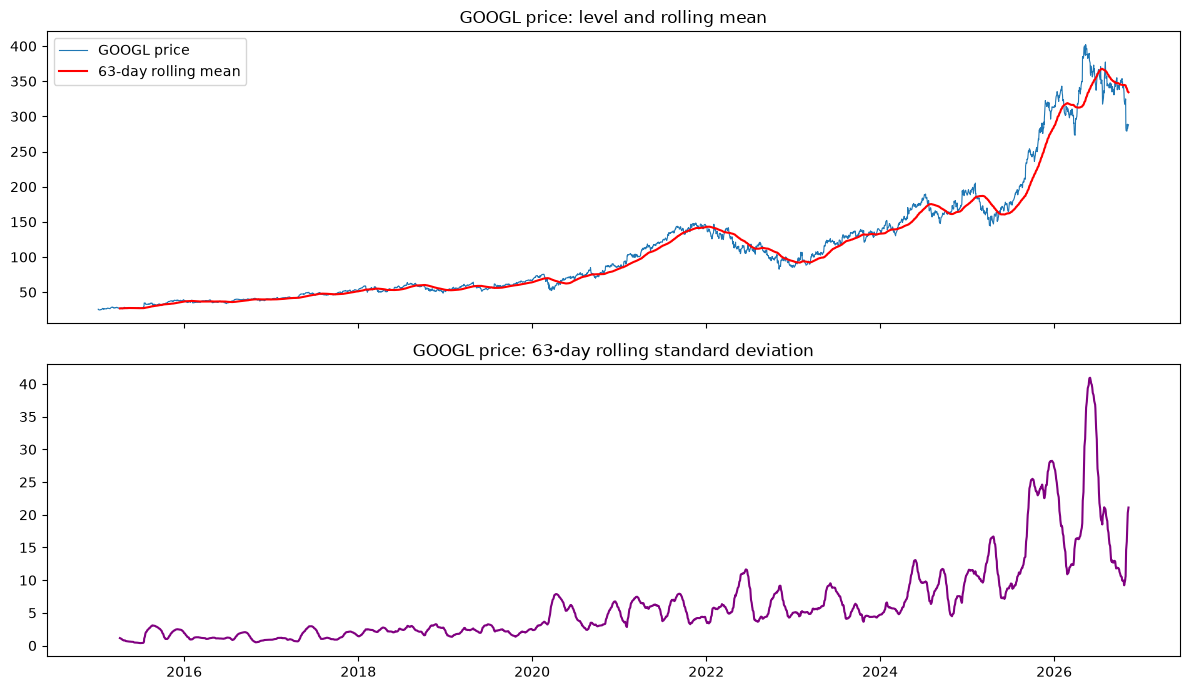

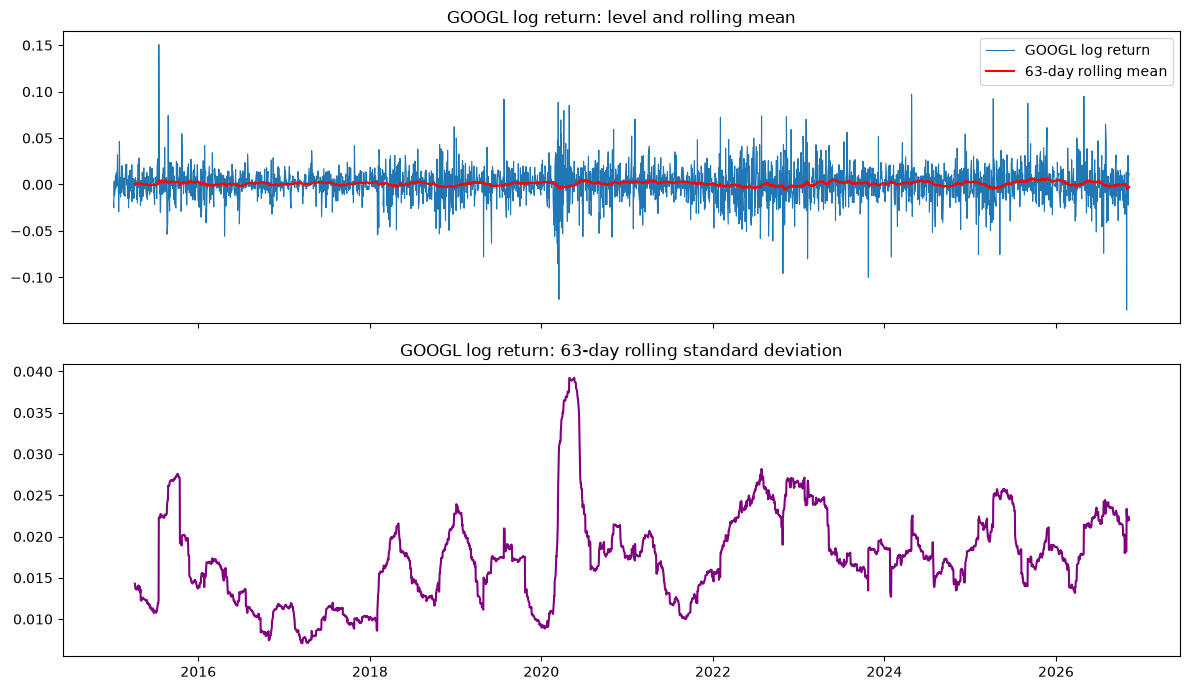

In [4]:
WINDOW = 63

def plot_with_rolling_stats(s, title):
    roll_mean = s.rolling(WINDOW).mean()
    roll_std = s.rolling(WINDOW).std()

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    ax1.plot(s.index, s, label=title, linewidth=0.8)
    ax1.plot(roll_mean.index, roll_mean, label=f"{WINDOW}-day rolling mean", color="red")
    ax1.set_title(f"{title}: level and rolling mean")
    ax1.legend()

    ax2.plot(roll_std.index, roll_std, color="purple")
    ax2.set_title(f"{title}: {WINDOW}-day rolling standard deviation")

    plt.tight_layout()
    plt.show()

plot_with_rolling_stats(series["price"], f"{config.TARGET_TICKER} price")
plot_with_rolling_stats(series["log_return"], f"{config.TARGET_TICKER} log return")


Expected pattern: the **price** panel's rolling mean drifts upward over the years (no fixed
level), while the **log return** panel's rolling mean hovers near zero and its rolling standard
deviation moves but stays within a bounded range rather than drifting off to a new level.
(That changing-but-bounded spread in the returns is volatility clustering — covered formally in
Step 8.)


## Step 4: Statistical Stationarity Tests — ADF and KPSS

- **ADF (Augmented Dickey-Fuller):** null hypothesis = *non-stationary* (has a unit root). A low
  p-value (below 0.05) lets us reject the null, i.e. evidence **for** stationarity.
- **KPSS:** null hypothesis = *stationary*. A low p-value (below 0.05) lets us reject the null,
  i.e. evidence **against** stationarity.

Running both and checking whether they agree is more convincing than relying on either alone.


In [5]:
def stationarity_verdict(s, name):
    s = s.dropna()
    adf_stat, adf_p, *_ = adfuller(s, autolag="AIC")
    kpss_stat, kpss_p, *_ = kpss(s, regression="c", nlags="auto")

    adf_says_stationary = adf_p < 0.05
    kpss_says_stationary = kpss_p >= 0.05  # KPSS fails to reject -> consistent with stationary

    return {
        "series": name,
        "ADF statistic": round(adf_stat, 4),
        "ADF p-value": round(adf_p, 4),
        "ADF verdict": "stationary" if adf_says_stationary else "non-stationary",
        "KPSS statistic": round(kpss_stat, 4),
        "KPSS p-value": round(kpss_p, 4),
        "KPSS verdict": "stationary" if kpss_says_stationary else "non-stationary",
        "Tests agree": adf_says_stationary == kpss_says_stationary,
    }

results = pd.DataFrame([
    stationarity_verdict(series["price"], "Price (level)"),
    stationarity_verdict(series["log_price"], "Log price (level)"),
    stationarity_verdict(series["price_change"], "Price change (1st difference)"),
    stationarity_verdict(series["log_return"], "Log return (1st difference of log price)"),
])
results


,series,ADF statistic,ADF p-value,ADF verdict,KPSS statistic,KPSS p-value,KPSS verdict,Tests agree
0,Price (level),-0.0366,0.9554,non-stationary,6.8324,0.01,non-stationary,True
1,Log price (level),-0.7422,0.8355,non-stationary,8.5056,0.01,non-stationary,True
2,Price change (1st difference),-9.8625,0.0000,stationary,0.1721,0.10,stationary,True
3,Log return (1st difference of log price),-18.5539,0.0000,stationary,0.0326,0.10,stationary,True


Expected result: the two **level** series (price, log price) should fail to look stationary
(ADF cannot reject its null; KPSS rejects its null), while the two **differenced** series (price
change, log return) should look stationary by both tests. This is the formal confirmation of
what Step 3's plots suggested.


## Step 5: Differencing and the Log Transform

`price_change` and `log_return` *are* the differenced series used above — first-order
differencing (`price.diff()`, `log_price.diff()`) is exactly what converts a non-stationary
random walk into a stationary series. The log transform is applied **before** differencing
when a series' variance itself grows with its level (common in prices): differencing the log
series stabilises the variance as well as the mean, which is why `log_return`, not raw
`price_change`, is the lab's preferred target.


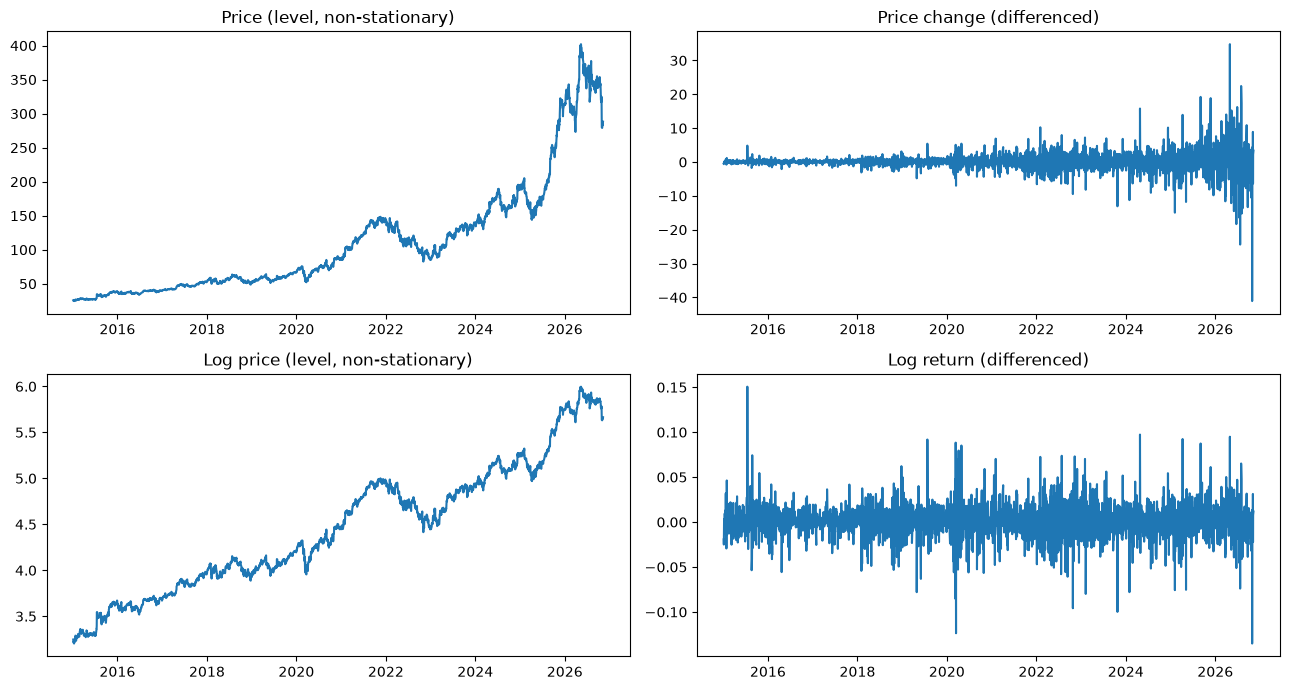

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
axes[0, 0].plot(series["price"]); axes[0, 0].set_title("Price (level, non-stationary)")
axes[0, 1].plot(series["price_change"]); axes[0, 1].set_title("Price change (differenced)")
axes[1, 0].plot(series["log_price"]); axes[1, 0].set_title("Log price (level, non-stationary)")
axes[1, 1].plot(series["log_return"]); axes[1, 1].set_title("Log return (differenced)")
plt.tight_layout()
plt.show()


## Step 6: Autocorrelation — ACF and PACF

- **ACF** shows the *total* correlation between a series and its own past, at each lag.
- **PACF** strips out the indirect effect of shorter lags, showing the *direct* relationship at
  each lag.

Where PACF cuts off tells you a candidate AR order (p); where ACF cuts off tells you a candidate
MA order (q) — this is exactly what Notebook 3 uses to choose ARIMA's `(p, d, q)`.


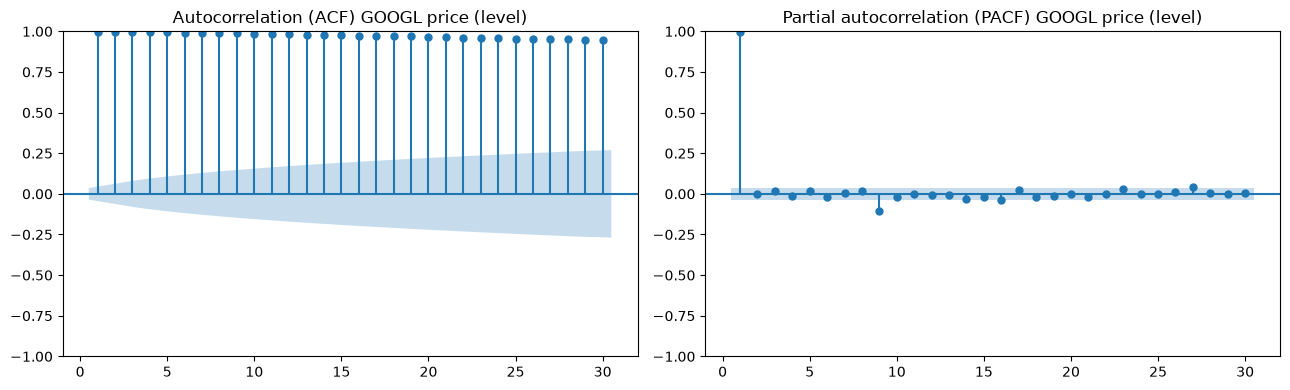

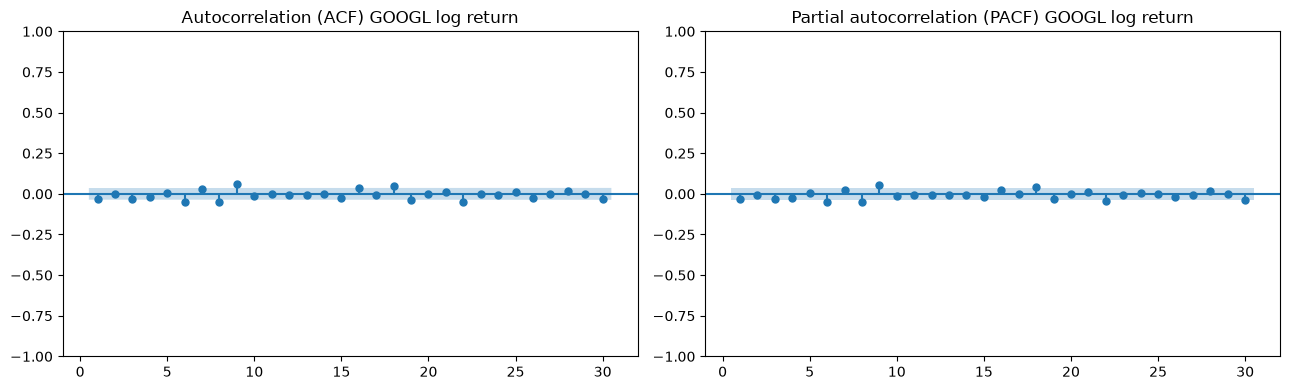

In [7]:
plot_acf_pacf(series["price"], title=f"{config.TARGET_TICKER} price (level)")
plot_acf_pacf(series["log_return"], title=f"{config.TARGET_TICKER} log return")


Expected pattern: the **price** level shows strong, slowly-decaying autocorrelation at almost
every lag (because a random walk is highly self-correlated), while the **log return** series
shows little or no significant autocorrelation beyond lag 0 — further evidence that returns
behave close to "unpredictable noise" rather than a trending series.


## Step 7: Spurious Regression

Two **unrelated** random walks can appear strongly correlated purely by chance, if you regress
their **levels**. Regressing their **returns** (differences) instead removes this illusion. We
demonstrate this using GOOGL and one of the macro predictors loaded in Step 2's dataset (gold).


In [8]:
other_price = data["GOLD"]
other_log_return = np.log(other_price / other_price.shift(1))

aligned_levels = pd.DataFrame({"msft_price": price, "gold_price": other_price}).dropna()
aligned_returns = pd.DataFrame({
    "msft_return": log_return, "gold_return": other_log_return
}).dropna()

def r_squared(y, x):
    x_with_const = sm.add_constant(x)
    model = sm.OLS(y, x_with_const).fit()
    return model.rsquared

r2_levels = r_squared(aligned_levels["msft_price"], aligned_levels["gold_price"])
r2_returns = r_squared(aligned_returns["msft_return"], aligned_returns["gold_return"])

print(f"R-squared regressing GOOGL PRICE on GOLD PRICE   (levels) : {r2_levels:.4f}")
print(f"R-squared regressing GOOGL RETURN on GOLD RETURN (returns): {r2_returns:.4f}")


R-squared regressing GOOGL PRICE on GOLD PRICE   (levels) : 0.9203
R-squared regressing GOOGL RETURN on GOLD RETURN (returns): 0.0025


Expected result: the **levels** regression typically shows a misleadingly high R-squared —
two series that both drift over the years will look "related" even with no real causal link.
The **returns** regression R-squared drops sharply, revealing how little of the relationship
was real. **Lesson:** always regress differenced (return) series, never raw price levels,
when testing whether one series genuinely predicts another.


## Step 8: Volatility Clustering — GARCH(1,1)

Calm and turbulent periods come in **clusters** rather than being spread evenly through time —
a big move tends to be followed by more big moves. A GARCH(1,1) model captures this with:

- **alpha[1]:** how much yesterday's shock affects today's variance.
- **beta[1]:** how much yesterday's variance persists into today.
- **nu** (if a Student's t distribution is used): controls how fat-tailed the distribution is.


In [9]:
# arch_model expects returns in percentage points for numerical stability.
returns_pct = series["log_return"].dropna() * 100

garch = arch_model(returns_pct, vol="Garch", p=1, q=1, dist="t")
garch_fit = garch.fit(disp="off")
print(garch_fit.summary())


                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   log_return   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -5640.93
Distribution:      Standardized Student's t   AIC:                           11291.9
Method:                  Maximum Likelihood   BIC:                           11321.9
                                              No. Observations:                 2980
Date:                      Fri, Nov 27 2026   Df Residuals:                     2979
Time:                              18:40:43   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

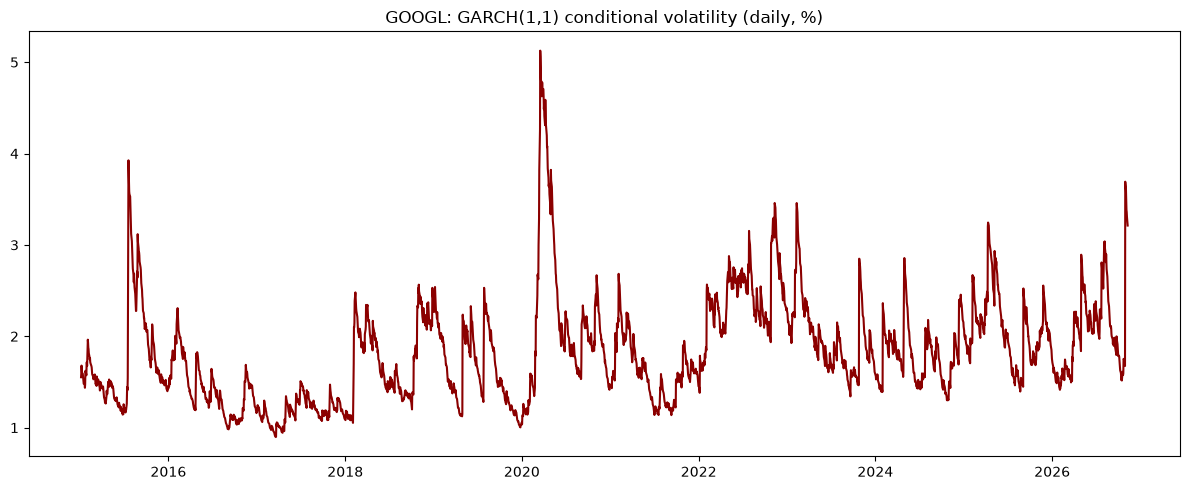

In [10]:
conditional_vol = garch_fit.conditional_volatility

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(conditional_vol.index, conditional_vol, color="darkred")
ax.set_title(f"{config.TARGET_TICKER}: GARCH(1,1) conditional volatility (daily, %)")
plt.tight_layout()
plt.show()


Expected pattern: the conditional-volatility plot should show clear clusters — multi-month
stretches where volatility sits noticeably higher than the surrounding calm periods (for
example around well-known market stress episodes), rather than a flat, constant line. A
statistically significant `alpha[1]` and `beta[1]` (check the p-values in the summary above)
confirms the clustering is real, not noise.


## Step 9: Conclusion (Written Verdict for This Notebook)

- **Price (and log price)** fail the stationarity tests: ADF cannot reject its "non-stationary"
  null, and KPSS rejects its "stationary" null. Visually, the rolling mean drifts over time —
  textbook random-walk behaviour.
- **Returns (log return)** pass both tests: ADF rejects "non-stationary", KPSS does not reject
  "stationary". Visually, the rolling mean sits near zero throughout.
- **ACF/PACF** reinforce this: price is highly autocorrelated at almost every lag; returns show
  little to no significant autocorrelation.
- **Spurious regression** shows that two price *levels* can look related purely by chance, while
  the same comparison on *returns* reveals how little of that relationship is genuine.
- **Volatility clustering** shows that even though returns are stationary in mean, their
  *variance* is not constant minute-to-minute — it clusters into calm and turbulent regimes,
  which GARCH models explicitly.

**Bottom line for the rest of the lab:** price is non-stationary, returns are (approximately)
stationary — this is why every forecasting model from Notebook 3 onward targets the **next-day
log return**, not the price itself.
